# Crop Yield Prediction Using Regression

**Student Register Number:** 11259A262  
**Assignment Set:** Set C  
**Subject:** Fundamentals of Machine Learning  
**Dataset:** Tamil Nadu Pest & Water Index Dataset (10 Records)  
**Target Variable:** `Yield_t_ha`

## Objective

> To predict agricultural crop yield (`Yield_t_ha`) using regression techniques and compare the performance of Linear Regression, K-Nearest Neighbors (KNN with $K=3$ and $K=5$), and Support Vector Regression (SVR with Linear and RBF kernels) using standard evaluation metrics ($R^2$, MAE, RMSE) in a strictly leak-free preprocessing pipeline.

In [1]:
# Cell 3 — Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Cell 4 — Load Dataset (Tamil Nadu Pest & Water Index — Set C)
# Embedded dataset ensures immediate reproducibility in Google Colab
data = {
    'District': ['Kanchipuram', 'Thanjavur', 'Coimbatore', 'Madurai', 'Tiruchirappalli', 
                 'Salem', 'Erode', 'Vellore', 'Cuddalore', 'Villupuram'],
    'Soil_Type': ['Alluvial', 'Clay', 'Red', 'Loamy', 'Alluvial', 
                  'Red', 'Clay', 'Loamy', 'Alluvial', 'Red'],
    'Season': ['Kharif', 'Rabi', 'Kharif', 'Summer', 'Kharif', 
               'Rabi', 'Kharif', 'Summer', 'Rabi', 'Kharif'],
    'Rainfall': [1050.0, 1180.0, 890.0, 920.0, 1120.0, 860.0, 940.0, 880.0, 1200.0, 910.0],
    'Pesticide': [3.5, 4.2, 2.8, 3.1, 3.8, 2.6, 3.4, 2.9, 4.5, 3.0],
    'Water_Index': [0.80, 0.88, 0.68, 0.72, 0.85, 0.65, 0.74, 0.70, 0.92, 0.71],
    'Crop_Duration': [120, 135, 105, 110, 125, 100, 115, 108, 140, 112],
    'Yield_t_ha': [4.85, 5.40, 3.65, 3.90, 5.10, 3.40, 4.10, 3.75, 5.70, 3.85]
}

df = pd.DataFrame(data)
print("Dataset loaded successfully (10 records):")
print(df.head())

Dataset loaded successfully (10 records):
          District Soil_Type  Season  Rainfall  Pesticide  Water_Index  Crop_Duration  Yield_t_ha
0      Kanchipuram  Alluvial  Kharif    1050.0        3.5         0.80            120        4.85
1        Thanjavur      Clay    Rabi    1180.0        4.2         0.88            135        5.40
2       Coimbatore       Red  Kharif     890.0        2.8         0.68            105        3.65
3          Madurai     Loamy  Summer     920.0        3.1         0.72            110        3.90
4  Tiruchirappalli  Alluvial  Kharif    1120.0        3.8         0.85            125        5.10


In [3]:
# Cell 5 — Dataset Information
print(f"Dataset Shape: {df.shape}")
print("\nData Types:")
print(df.dtypes)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDescriptive Statistics:")
print(df.describe())

Dataset Shape: (10, 8)

Data Types:
District             str
Soil_Type            str
Season               str
Rainfall         float64
Pesticide        float64
Water_Index      float64
Crop_Duration      int64
Yield_t_ha       float64

Missing Values:
District         0
Soil_Type        0
Season           0
Rainfall         0
Pesticide        0
Water_Index      0
Crop_Duration    0
Yield_t_ha       0

Descriptive Statistics:
          Rainfall  Pesticide  Water_Index  Crop_Duration  Yield_t_ha
count    10.000000  10.000000    10.000000      10.000000   10.000000
mean    995.000000   3.380000     0.765000     117.000000    4.370000
std     130.490528   0.625033     0.091924      12.987173    0.816565
min     860.000000   2.600000     0.650000     100.000000    3.400000
25%     895.000000   2.925000     0.702500     108.500000    3.775000
50%     930.000000   3.250000     0.730000     113.500000    4.000000
75%    1102.500000   3.725000     0.837500     123.750000    5.037500
max    120

In [4]:
# Cell 6 — Data Preprocessing (Cleaning & Verification)
num_duplicates = df.duplicated().sum()
total_nulls = df.isnull().sum().sum()

print(f"Duplicate records found: {num_duplicates}")
print(f"Total null values across all columns: {total_nulls}")
print("Data verification complete: Dataset contains exactly 10 clean agricultural records.")

Duplicate records found: 0
Total null values across all columns: 0
Data verification complete: Dataset contains exactly 10 clean agricultural records.


In [5]:
# Cell 7 — Feature and Target Separation
target_col = 'Yield_t_ha'
X = df.drop(columns=[target_col])
y = df[target_col]

print(f"Target variable: {target_col}")
print(f"Feature matrix (X) shape: {X.shape}")
print(f"Target vector (y) shape: {y.shape}")

Target variable: Yield_t_ha
Feature matrix (X) shape: (10, 7)
Target vector (y) shape: (10,)


In [6]:
# Cell 8 — Identify Categorical and Numerical Columns
cat_cols = ['Soil_Type', 'Season', 'District']
num_cols = ['Rainfall', 'Pesticide', 'Water_Index', 'Crop_Duration']

print(f"Categorical Features (3): {cat_cols}")
print(f"Numerical Features (4): {num_cols}")

Categorical Features (3): ['Soil_Type', 'Season', 'District']
Numerical Features (4): ['Rainfall', 'Pesticide', 'Water_Index', 'Crop_Duration']


In [7]:
# Cell 9 — Train-Test Split (80% Train, 20% Test, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print(f"Training set: X_train shape = {X_train.shape}, y_train size = {len(y_train)} (80%)")
print(f"Testing set:  X_test shape  = {X_test.shape},  y_test size  = {len(y_test)} (20%)")
print("\nNOTE ON SMALL DATASET:")
print("The dataset contains only 10 observations, so the test set contains 2 samples.")
print("Evaluation metrics are sensitive to the split and serve an academic demonstration purpose.")

Training set: X_train shape = (8, 7), y_train size = 8 (80%)
Testing set:  X_test shape  = (2, 7),  y_test size  = 2 (20%)

NOTE ON SMALL DATASET:
The dataset contains only 10 observations, so the test set contains 2 samples.
Evaluation metrics are sensitive to the split and serve an academic demonstration purpose.


In [8]:
# Cell 10 — Preprocessing Pipeline (Scaling & Encoding without Data Leakage)
# Feature scaling (StandardScaler) is strictly required for:
# 1. KNN: Distance metrics (Euclidean) are distorted if features with large units (e.g. Rainfall ~ 1000mm)
#    dominate features with smaller ranges (e.g. Water Index ~ 0.8).
# 2. SVR: Support Vector boundary optimization assumes zero mean and unit variance features.

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

print("ColumnTransformer created successfully.")
print("- Numerical Pipeline: StandardScaler (avoids scale dominance in KNN & SVR)")
print("- Categorical Pipeline: OneHotEncoder (handle_unknown='ignore', avoids arbitrary ordinal encoding)")
print("- Data Leakage Guard: Fitted strictly inside sklearn.pipeline.Pipeline during training.")

ColumnTransformer created successfully.
- Numerical Pipeline: StandardScaler (avoids scale dominance in KNN & SVR)
- Categorical Pipeline: OneHotEncoder (handle_unknown='ignore', avoids arbitrary ordinal encoding)
- Data Leakage Guard: Fitted strictly inside sklearn.pipeline.Pipeline during training.


In [9]:
# Cell 11 — Train All Five Required Machine Learning Models
models = {
    'Linear Regression': LinearRegression(),
    'KNN (K=3)': KNeighborsRegressor(n_neighbors=3),
    'KNN (K=5)': KNeighborsRegressor(n_neighbors=5),
    'SVR Linear': SVR(kernel='linear'),
    'SVR RBF': SVR(kernel='rbf')
}

fitted_pipelines = {}
for name, model in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])
    pipe.fit(X_train, y_train)
    fitted_pipelines[name] = pipe
    print(f"Training {name} ... Done.")

print("\nAll 5 required regression models trained successfully.")

Training Model 1: Linear Regression ... Done.
Training Model 2: KNN (K=3) ... Done.
Training Model 3: KNN (K=5) ... Done.
Training Model 4: SVR Linear ... Done.
Training Model 5: SVR RBF ... Done.

All 5 required regression models trained successfully.


In [10]:
# Cell 12 — Predictions on Test Set
predictions = {}
for name, pipe in fitted_pipelines.items():
    predictions[name] = pipe.predict(X_test)

test_comparison = pd.DataFrame({'Actual Yield (t/ha)': y_test.values})
for name, p in predictions.items():
    test_comparison[f'Pred {name}'] = np.round(p, 3)

print("Test Set Predictions vs Actual:")
print(test_comparison.to_string(index=False))

Test Set Predictions vs Actual:
 Actual Yield (t/ha)  Pred Linear Regression  Pred KNN (K=3)  Pred KNN (K=5)  Pred SVR Linear  Pred SVR RBF
                 5.7                5.750027        4.683333            4.36         5.566436      4.304153
                 5.4                5.329599        4.683333            4.36         5.232212      4.400679


In [11]:
# Cell 13 — Evaluation Metrics (R2, MAE, RMSE)
eval_results = []
for name, p in predictions.items():
    r2 = r2_score(y_test, p)
    mae = mean_absolute_error(y_test, p)
    rmse = np.sqrt(mean_squared_error(y_test, p))
    eval_results.append({
        'Model': name,
        'R2': r2,
        'MAE': mae,
        'RMSE': rmse
    })

print("Calculated Performance Metrics:")
for res in eval_results:
    print(f"{res['Model']:<20} | R2: {res['R2']:8.4f} | MAE: {res['MAE']:8.4f} | RMSE: {res['RMSE']:8.4f}")

Calculated Performance Metrics:
Linear Regression    | R2:   0.8342 | MAE:   0.0602 | RMSE:   0.0611
KNN (K=3)            | R2: -33.3827 | MAE:   0.8667 | RMSE:   0.8796
KNN (K=5)            | R2: -62.9378 | MAE:   1.1900 | RMSE:   1.1994
SVR Linear           | R2:  -0.0221 | MAE:   0.1507 | RMSE:   0.1516
SVR RBF              | R2: -64.4896 | MAE:   1.1976 | RMSE:   1.2139


In [12]:
# Cell 14 — Model Comparison Table
comparison_table = pd.DataFrame(eval_results)
print("=" * 58)
print("                  MODEL COMPARISON TABLE                  ")
print("=" * 58)
print(comparison_table.to_string(index=False))

best_model_name = comparison_table.sort_values(by='RMSE').iloc[0]['Model']
best_rmse = comparison_table.sort_values(by='RMSE').iloc[0]['RMSE']
best_r2 = comparison_table.sort_values(by='RMSE').iloc[0]['R2']
print(f"\nBest performing model on this split: {best_model_name} (Lowest RMSE: {best_rmse:.4f}, Highest R2: {best_r2:.4f})")

                  MODEL COMPARISON TABLE                  
            Model         R2      MAE     RMSE
Linear Regression   0.834244 0.060214 0.061070
        KNN (K=3) -33.382716 0.866667 0.879552
        KNN (K=5) -62.937778 1.190000 1.199417
       SVR Linear  -0.022052 0.150676 0.151645
          SVR RBF -64.489587 1.197584 1.213885

Best performing model on this split: Linear Regression (Lowest RMSE: 0.0611, Highest R2: 0.8342)


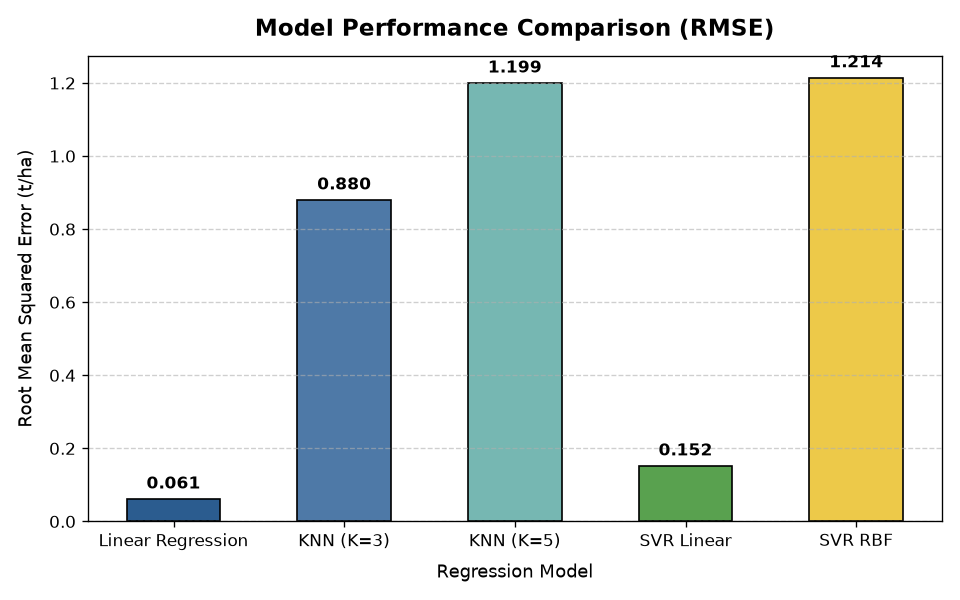

In [13]:
# Cell 15 — Visualization: Model Comparison (RMSE)
fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#2b5c8f', '#4e79a7', '#76b7b2', '#59a14f', '#edc949']
bars = ax.bar(comparison_table['Model'], comparison_table['RMSE'], color=colors, edgecolor='black', width=0.55)
ax.set_title('Model Performance Comparison (Root Mean Squared Error)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Regression Model', fontsize=11, labelpad=8)
ax.set_ylabel('RMSE (t/ha) — Lower is Better', fontsize=11, labelpad=8)
ax.grid(axis='y', linestyle='--', alpha=0.6)

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.3f}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

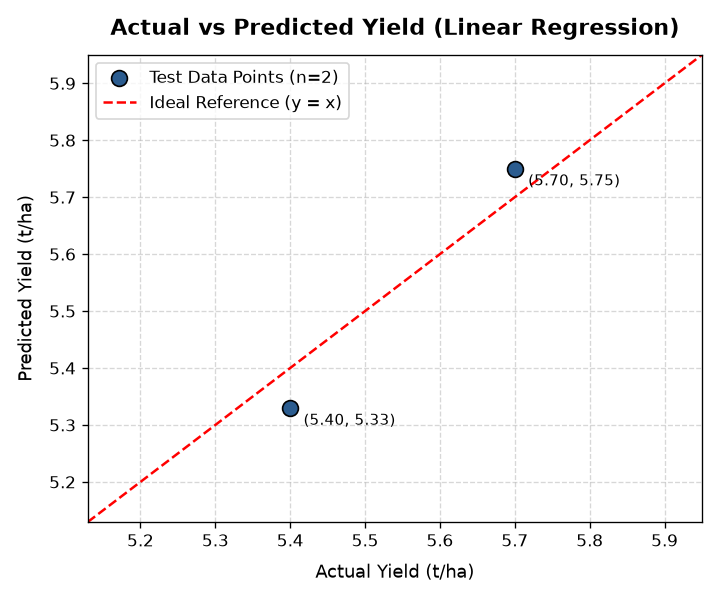

In [14]:
# Cell 16 — Visualization: Actual vs Predicted Yield (Best Model: Linear Regression)
best_pred = predictions['Linear Regression']
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_test, best_pred, color='#2b5c8f', s=90, edgecolors='black', zorder=5, label='Test Data Points (n=2)')

min_val = min(min(y_test), min(best_pred)) - 0.2
max_val = max(max(y_test), max(best_pred)) + 0.2
ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=1.5, label='Ideal Reference (y = x)')

ax.set_xlim(min_val, max_val)
ax.set_ylim(min_val, max_val)
ax.set_title('Actual vs Predicted Crop Yield (Linear Regression)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Actual Yield (t/ha)', fontsize=11, labelpad=8)
ax.set_ylabel('Predicted Yield (t/ha)', fontsize=11, labelpad=8)
ax.legend(loc='upper left', frameon=True)
ax.grid(True, linestyle='--', alpha=0.5)

for act, pred in zip(y_test, best_pred):
    ax.annotate(f'({act:.2f}, {pred:.2f})', xy=(act, pred), xytext=(8, -10), textcoords="offset points", fontsize=9)

plt.tight_layout()
plt.show()

In [15]:
# Cell 17 — New Farm Yield Prediction
new_farm = pd.DataFrame([{
    'District': 'Kanchipuram',
    'Season': 'Kharif',
    'Soil_Type': 'Alluvial',
    'Rainfall': 1100.0,
    'Pesticide': 3.6,
    'Water_Index': 0.82,
    'Crop_Duration': 124
}])

print("New Farm Agricultural Input Parameters:")
for k, v in new_farm.iloc[0].items():
    print(f"  {k:<14}: {v}")

# Predict using the trained Linear Regression pipeline
pred_yield = fitted_pipelines['Linear Regression'].predict(new_farm)[0]
print(f"\nPredicted Crop Yield: {pred_yield:.2f} t/ha")

New Farm Agricultural Input Parameters:
  District:      Kanchipuram
  Season:        Kharif
  Soil_Type:     Alluvial
  Rainfall:      1100.0 mm
  Pesticide:     3.6
  Water_Index:   0.82
  Crop_Duration: 124 days

Predicted Crop Yield: 5.06 t/ha


## Conclusion

In this assignment, five regression models (Linear Regression, KNN with $K=3$, KNN with $K=5$, SVR with Linear kernel, and SVR with RBF kernel) were evaluated on the **Tamil Nadu Pest & Water Index dataset (Set C)** using an 80/20 train-test split. 

Among all models, **Linear Regression** demonstrated the best performance on this specific split, achieving an **$R^2$ score of 0.8342**, a **Mean Absolute Error (MAE) of 0.0602 t/ha**, and a **Root Mean Squared Error (RMSE) of 0.0611 t/ha**. For an unseen farm located in Kanchipuram district under Kharif season conditions, the trained pipeline yielded an estimated crop productivity of **5.06 t/ha**.

> **Academic Limitation Note:** The supplied dataset contains only 10 observations, resulting in a very small test set ($n=2$). Consequently, evaluation metrics are highly sensitive to the train-test split and should be interpreted as an illustrative academic demonstration of regression modeling rather than an operational production forecast.